In [1]:
%load_ext autoreload

### Importing and loading data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("problem1.csv")

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

y_train = train["y"]
y_test = test["y"]

## Info about data

In [3]:
print(train.info())
print(train[["x0", "x1", "y"]].isnull().sum())
print(train["y"].value_counts())
print(train["y"].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
Index: 1006 entries, 0 to 1005
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x0      1006 non-null   float64
 1   x1      1006 non-null   float64
 2   y       1006 non-null   float64
 3   split   1006 non-null   object 
dtypes: float64(3), object(1)
memory usage: 39.3+ KB
None
x0    0
x1    0
y     0
dtype: int64
y
0.0    930
1.0     76
Name: count, dtype: int64
y
0.0    0.924453
1.0    0.075547
Name: proportion, dtype: float64


### Adding possible features

In [4]:
def add_features(data):
    result = data[["x0", "x1"]].copy()

    result["sum"] = result["x0"] + result["x1"]
    result["difference"] = result["x0"] - result["x1"]
    result["radius"] = np.sqrt(
        result["x0"]**2 + result["x1"]**2
    )

    return result


X_train_all = add_features(train)
X_test_all = add_features(test)

print(X_train_all.head())

         x0        x1       sum  difference    radius
0  1.469311 -0.816098  0.653213    2.285408  1.680741
1  1.558715 -0.966211  0.592503    2.524926  1.833891
2  0.063461  0.206364  0.269825   -0.142902  0.215901
3  0.025497  0.326340  0.351838   -0.300843  0.327335
4  0.130497  0.456340  0.586838   -0.325843  0.474632


### Only baseline features

In [33]:
baseline_features = ["x0", "x1"]

X_train_baseline = X_train_all[baseline_features]
X_test_baseline = X_test_all[baseline_features]

baseline_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42 # For reproducibility. Same as set_seed(42) in R.
)


baseline_model.fit(X_train_baseline, y_train)

baseline_prediction = baseline_model.predict(X_test_baseline)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_prediction))

print(confusion_matrix(y_test, baseline_prediction))

Baseline accuracy: 0.5866666666666667
[[148   2]
 [122  28]]


In [34]:
feature_sets = {
    "x0, x1": ["x0", "x1"],
    "sum": ["sum"],
    "x0, x1, sum": ["x0", "x1", "sum"],
    "sum, difference": ["sum", "difference"],
    "all features": [
        "x0",
        "x1",
        "sum",
        "difference",
        "radius"
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42 # For reproducibility. Same as set_seed(42) in R.
)

results = []

for name, features in feature_sets.items():
    for depth in [1, 2, 3, 4, 5, 8, 12]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=3,
            random_state=42
        )

        scores = cross_val_score(
            model,
            X_train_all[features],
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        results.append({
            "features": name,
            "depth": depth,
            "cv_accuracy_mean": scores.mean(),
            "cv_accuracy_std": scores.std()
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "cv_accuracy_mean",
    ascending=False
)

results_df.head(10)

,features,depth,cv_accuracy_mean,cv_accuracy_std
8,sum,2,0.928432,0.003927
9,sum,3,0.925447,0.008326
33,all features,8,0.924462,0.013806
21,"sum, difference",1,0.924457,0.001832
28,all features,1,0.924457,0.001832
0,"x0, x1",1,0.924457,0.001832
7,sum,1,0.924457,0.001832
14,"x0, x1, sum",1,0.924457,0.001832
26,"sum, difference",8,0.923472,0.010133
18,"x0, x1, sum",5,0.923447,0.012087


Note that scores all seem really similar and they are based only on training dataset.

In [9]:
print(results_df.to_string(index=False))

       features  depth  cv_accuracy_mean  cv_accuracy_std
            sum      2          0.928432         0.003927
            sum      3          0.925447         0.008326
   all features      8          0.924462         0.013806
sum, difference      1          0.924457         0.001832
   all features      1          0.924457         0.001832
         x0, x1      1          0.924457         0.001832
            sum      1          0.924457         0.001832
    x0, x1, sum      1          0.924457         0.001832
sum, difference      8          0.923472         0.010133
    x0, x1, sum      5          0.923447         0.012087
   all features      4          0.922487         0.016096
    x0, x1, sum      3          0.922477         0.011075
         x0, x1      5          0.921526         0.028823
sum, difference      5          0.921492         0.014755
sum, difference     12          0.921477         0.010578
    x0, x1, sum      2          0.921467         0.013520
sum, differenc

In [54]:
features = ["x0", "x1"]

for class_weight in [None, "balanced"]:
    model = DecisionTreeClassifier(
        max_depth=1,
        min_samples_leaf=3,
        class_weight=class_weight,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train_all[features],
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(
        f"class_weight={class_weight}, "
        f"CV accuracy={scores.mean():.3f}"
    )

class_weight=None, CV accuracy=0.924
class_weight=balanced, CV accuracy=0.878


In [56]:
selected_features = ["x0", "x1"]
selected_depth = 1
selected_weight = "balanced"

In [57]:
final_model = DecisionTreeClassifier(
    max_depth=selected_depth,
    min_samples_leaf=3,
    class_weight=selected_weight,
    random_state=42
)

final_model.fit(
    X_train_all[selected_features],
    y_train
)

final_prediction = final_model.predict(
    X_test_all[selected_features]
)

In [58]:
print("Test accuracy:",
      accuracy_score(y_test, final_prediction))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, final_prediction))

print("\nClassification report:")
print(classification_report(
    y_test,
    final_prediction,
    zero_division=0
))

Test accuracy: 0.8733333333333333

Confusion matrix:
[[125  25]
 [ 13 137]]

Classification report:
              precision    recall  f1-score   support

         0.0       0.91      0.83      0.87       150
         1.0       0.85      0.91      0.88       150

    accuracy                           0.87       300
   macro avg       0.88      0.87      0.87       300
weighted avg       0.88      0.87      0.87       300



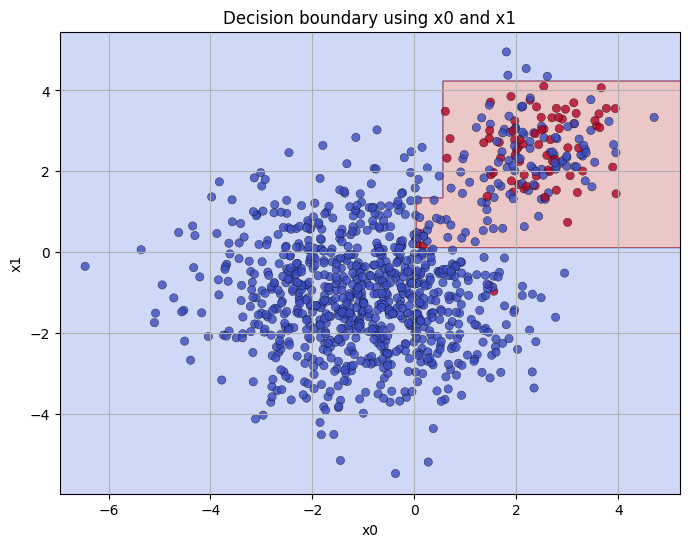

In [61]:
from matplotlib.colors import ListedColormap

# Features modellen ble trent på
features = ["x0", "x1"]

# Tren modellen
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
    class_weight="balanced"
)

model.fit(train[features], train["y"])

# Lag et rutenett over x0- og x1-området
x0_min, x0_max = df["x0"].min() - 0.5, df["x0"].max() + 0.5
x1_min, x1_max = df["x1"].min() - 0.5, df["x1"].max() + 0.5

x0_grid, x1_grid = np.meshgrid(
    np.linspace(x0_min, x0_max, 400),
    np.linspace(x1_min, x1_max, 400)
)

grid = pd.DataFrame({
    "x0": x0_grid.ravel(),
    "x1": x1_grid.ravel()
})

# Prediksjon for hvert punkt i rutenettet
grid_prediction = model.predict(grid)
grid_prediction = grid_prediction.reshape(x0_grid.shape)

# Tegn beslutningsområdene
plt.figure(figsize=(8, 6))

plt.contourf(
    x0_grid,
    x1_grid,
    grid_prediction,
    alpha=0.25,
    cmap=ListedColormap(["royalblue", "firebrick"])
)

# Tegn treningspunktene oppå
plt.scatter(
    train["x0"],
    train["x1"],
    c=train["y"],
    cmap="coolwarm",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.8
)

plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Decision boundary using x0 and x1")
plt.grid(True)
plt.show()